In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned dataset
df = pd.read_csv("/content/clean_dataset.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 32313
Columns: 15


,order_id,created_at,website_session_id,user_id,primary_product_id,items_purchased,price_usd,cogs_usd,year,month,month_name,revenue_usd,total_cost_usd,profit_usd,profit_margin_pct
0,1,2012-03-19 10:42:46,20,20,1,1,49.99,19.49,2012,3,March,49.99,19.49,30.5,61.012202
1,2,2012-03-19 19:27:37,104,104,1,1,49.99,19.49,2012,3,March,49.99,19.49,30.5,61.012202
2,3,2012-03-20 06:44:45,147,147,1,1,49.99,19.49,2012,3,March,49.99,19.49,30.5,61.012202
3,4,2012-03-20 09:41:45,160,160,1,1,49.99,19.49,2012,3,March,49.99,19.49,30.5,61.012202
4,5,2012-03-20 11:28:15,177,177,1,1,49.99,19.49,2012,3,March,49.99,19.49,30.5,61.012202


In [17]:
# ==========================================
# DESCRIPTIVE STATISTICS
# ==========================================

numeric_columns = [
    "items_purchased",
    "price_usd",
    "cogs_usd",
    "revenue_usd",
    "total_cost_usd",
    "profit_usd",
    "profit_margin_pct"
]

stats = df[numeric_columns].describe().T

stats["median"] = df[numeric_columns].median()

stats = stats[
    ["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max"]
]

stats

,count,mean,median,std,min,25%,50%,75%,max
items_purchased,32313.0,1.238666,1.000000,0.426274,1.000000,1.000000,1.000000,1.000000,2.000000
price_usd,32313.0,59.991636,49.990000,17.808771,29.990000,49.990000,49.990000,59.990000,109.980000
cogs_usd,32313.0,22.355406,19.490000,6.238621,9.490000,19.490000,19.490000,22.490000,41.980000
revenue_usd,32313.0,81.292715,49.990000,55.675254,29.990000,49.990000,49.990000,59.990000,219.960000
total_cost_usd,32313.0,29.988859,19.490000,19.709418,9.490000,19.490000,19.490000,22.490000,83.960000
profit_usd,32313.0,51.303856,30.500000,36.072294,20.500000,30.500000,30.500000,37.500000,138.000000
profit_margin_pct,32313.0,62.561173,61.012202,2.317615,61.012202,61.012202,61.012202,63.765941,68.493151


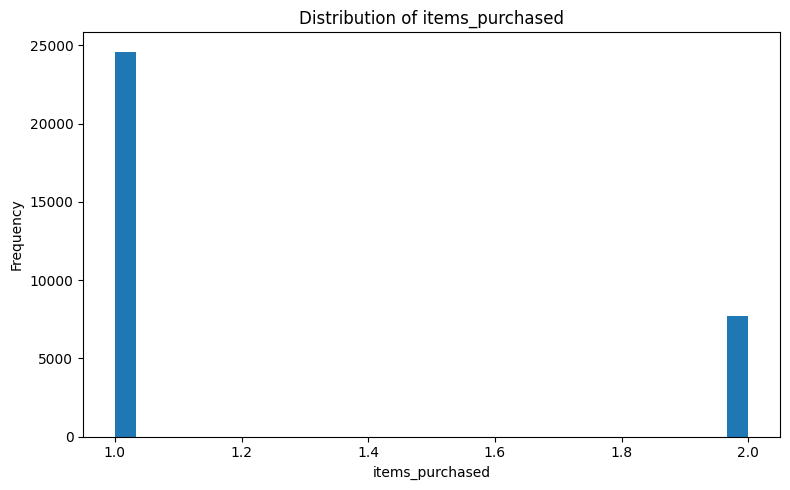

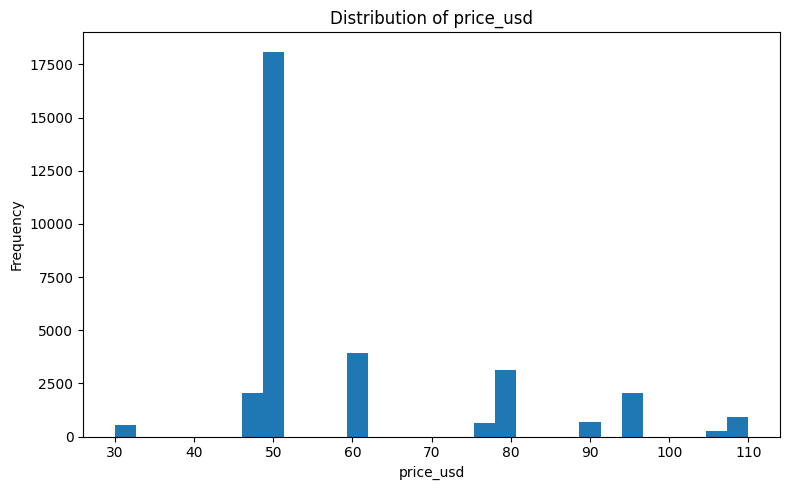

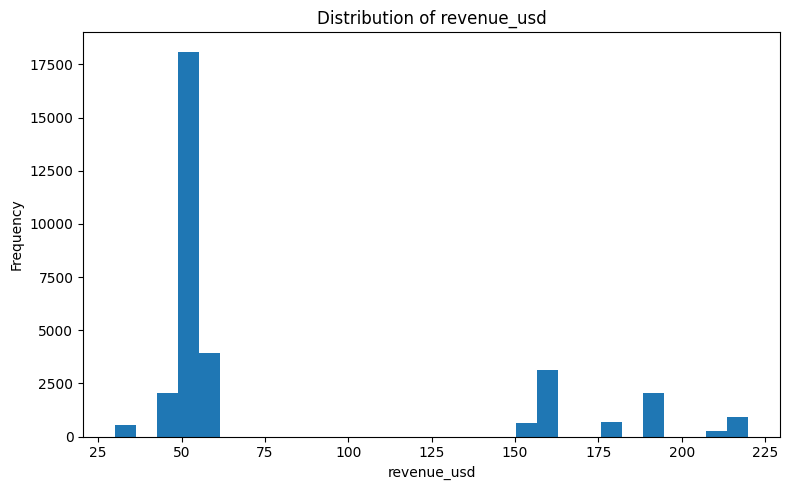

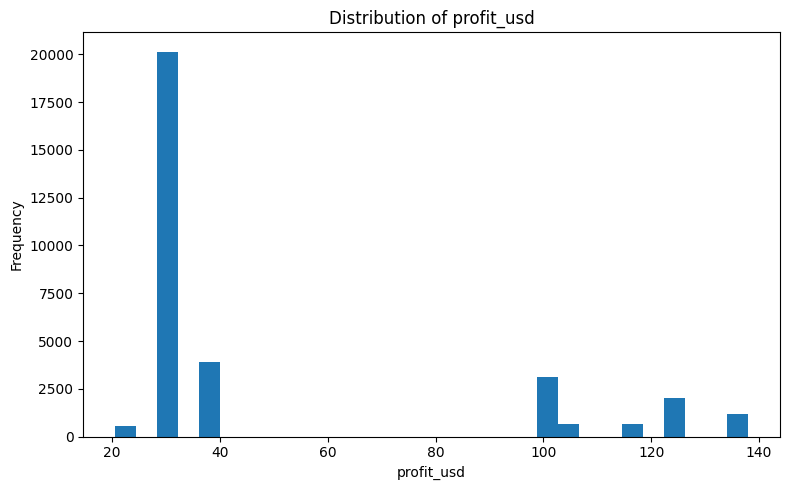

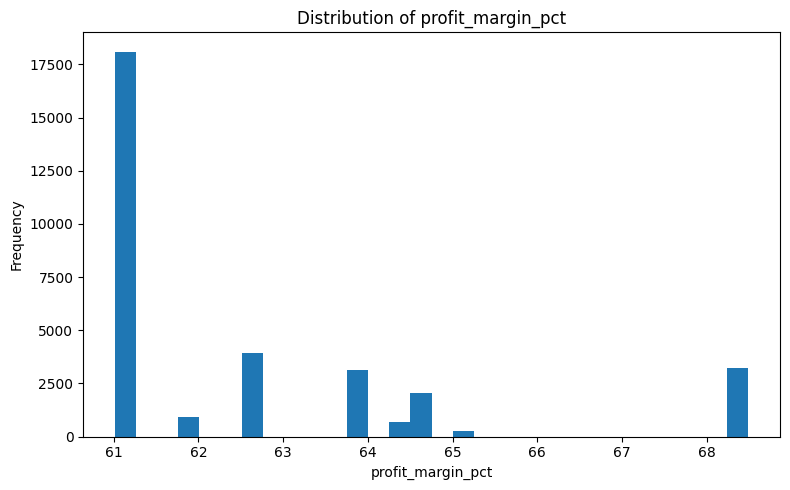

In [18]:
# ==========================================
# HISTOGRAM DISTRIBUTIONS
# ==========================================

hist_columns = [
    "items_purchased",
    "price_usd",
    "revenue_usd",
    "profit_usd",
    "profit_margin_pct"
]

for col in hist_columns:
    plt.figure(figsize=(8, 5))
    plt.hist(df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

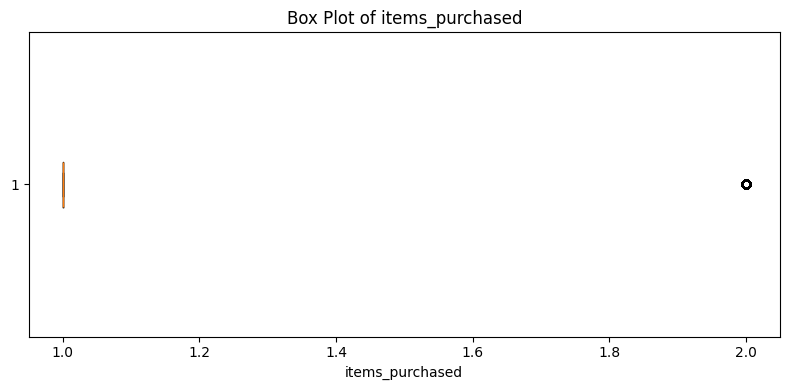

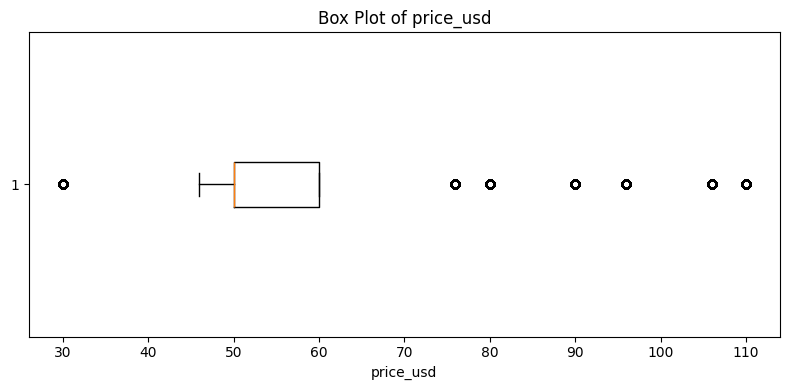

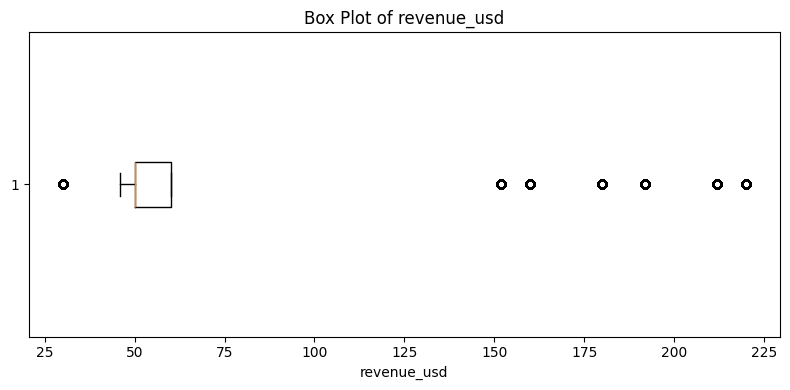

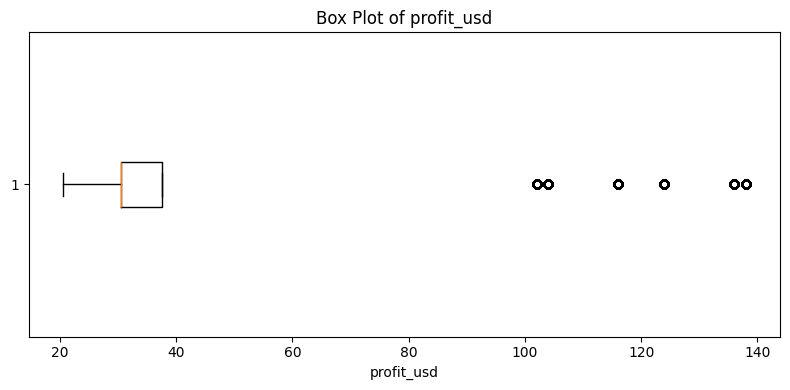

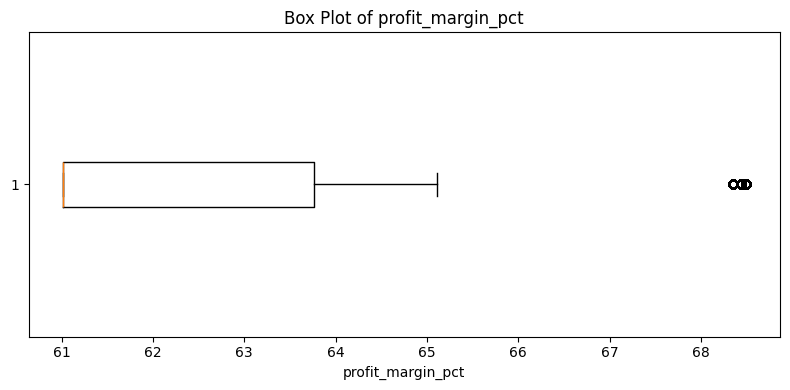

In [19]:
# ==========================================
# BOX PLOTS FOR ANOMALY DETECTION
# ==========================================

box_columns = [
    "items_purchased",
    "price_usd",
    "revenue_usd",
    "profit_usd",
    "profit_margin_pct"
]

for col in box_columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

===== CORRELATION MATRIX =====


,items_purchased,price_usd,cogs_usd,revenue_usd,total_cost_usd,profit_usd,profit_margin_pct
items_purchased,1.00,0.92,0.86,0.98,0.97,0.98,0.41
price_usd,0.92,1.00,0.98,0.98,0.98,0.97,0.25
cogs_usd,0.86,0.98,1.00,0.94,0.96,0.93,0.07
revenue_usd,0.98,0.98,0.94,1.00,1.00,1.00,0.35
total_cost_usd,0.97,0.98,0.96,1.00,1.00,0.99,0.28
profit_usd,0.98,0.97,0.93,1.00,0.99,1.00,0.38
profit_margin_pct,0.41,0.25,0.07,0.35,0.28,0.38,1.00


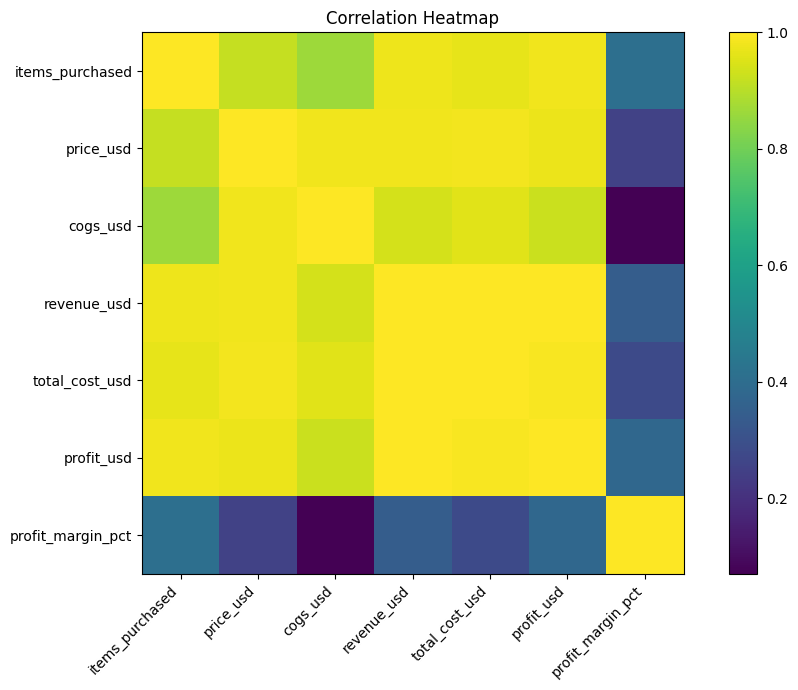

In [20]:
# ==========================================
# CORRELATION MATRIX & HEATMAP
# ==========================================

correlation_columns = [
    "items_purchased",
    "price_usd",
    "cogs_usd",
    "revenue_usd",
    "total_cost_usd",
    "profit_usd",
    "profit_margin_pct"
]

corr_matrix = df[correlation_columns].corr()

print("===== CORRELATION MATRIX =====")
display(corr_matrix.round(2))

# Heatmap
plt.figure(figsize=(10, 7))

plt.imshow(corr_matrix, interpolation="nearest")
plt.colorbar()

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

In [21]:
# ==========================================
# BUSINESS HYPOTHESIS TESTING
# ==========================================

from scipy.stats import pearsonr

# Hypothesis 1: Price vs Revenue
r1, p1 = pearsonr(
    df["price_usd"],
    df["revenue_usd"]
)

# Hypothesis 2: Price vs Profit
r2, p2 = pearsonr(
    df["price_usd"],
    df["profit_usd"]
)

# Hypothesis 3: COGS vs Profit
r3, p3 = pearsonr(
    df["cogs_usd"],
    df["profit_usd"]
)

print("===== BUSINESS HYPOTHESIS TEST RESULTS =====\n")

print("Hypothesis 1: Price vs Revenue")
print(f"Correlation: {r1:.4f}")
print(f"P-value: {p1:.6f}")

print("\nHypothesis 2: Price vs Profit")
print(f"Correlation: {r2:.4f}")
print(f"P-value: {p2:.6f}")

print("\nHypothesis 3: COGS vs Profit")
print(f"Correlation: {r3:.4f}")
print(f"P-value: {p3:.6f}")

===== BUSINESS HYPOTHESIS TEST RESULTS =====

Hypothesis 1: Price vs Revenue
Correlation: 0.9783
P-value: 0.000000

Hypothesis 2: Price vs Profit
Correlation: 0.9731
P-value: 0.000000

Hypothesis 3: COGS vs Profit
Correlation: 0.9270
P-value: 0.000000


# Key EDA Findings

## Top 5 Business Insights

### 1. Strong Price–Revenue Association
The analysis shows a very strong positive correlation between product price and revenue (**r = 0.9783, p < 0.05**). This indicates a strong statistical association between the two variables in the analyzed dataset.

### 2. Strong Price–Profit Association
Product price and profit also show a very strong positive correlation (**r = 0.9731, p < 0.05**). Higher-priced transactions are statistically associated with higher profit values in this dataset.

### 3. Strong COGS–Profit Association
COGS and profit have a strong positive correlation (**r = 0.9270, p < 0.05**). This indicates a strong statistical association between cost of goods sold and profit across the analyzed transactions.

### 4. Purchase Quantity Distribution
The `items_purchased` variable contains only 1 and 2 units per transaction. The distribution is concentrated around these two values, with one-unit purchases occurring substantially more frequently.

### 5. Profit Margin Shows Limited Variation
The descriptive statistics show that `profit_margin_pct` has a relatively small standard deviation compared with its mean, indicating that profit margins are fairly concentrated around the dataset's central value.

## Statistical Note

All three tested hypotheses produced p-values below the **0.05 significance level**, indicating statistically significant associations in the analyzed sample.

These results describe **correlation/association and do not establish causation**.